# Сверточная сеть
В этом ноутбуке мы расширим предыдущий и создадим первую сверточную сеть

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import ToTensor
from matplotlib import pyplot as plt

In [2]:
import os
import pandas as pd
from torchvision.io import read_image


# Создание датасета

Загрузим FashionMNIST (https://github.com/zalandoresearch/fashion-mnist)


In [3]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

100%|██████████| 26.4M/26.4M [00:12<00:00, 2.17MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 1.27MB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 2.07MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]


In [4]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}

In [5]:
def plot_samples(data, labels_map, cols=3, rows=3):
    figure = plt.figure(figsize=(8, 8))
    for i in range(1, cols * rows + 1):
        sample_idx = torch.randint(len(data), size=(1,)).item()
        img, label = data[sample_idx]
        figure.add_subplot(rows, cols, i)
        if type(label) == torch.Tensor:
            plt.title(labels_map[label.item()])
        else:
            plt.title(labels_map[label])
        plt.axis("off")
        plt.imshow(img.squeeze(), cmap="gray")
    plt.show()

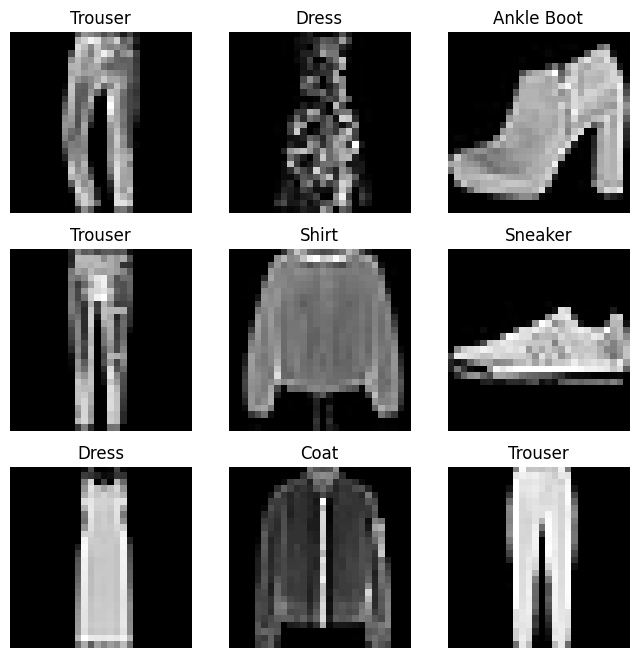

In [6]:
plot_samples(train_data, labels_map, cols=3, rows=3)

In [7]:
train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


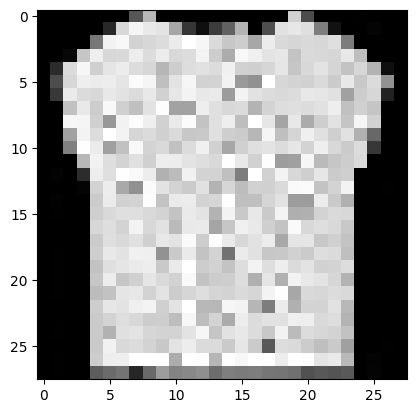

Label: 0


In [8]:
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze().reshape(28,28)
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

In [9]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")


Using cpu device


Теперь создадим класс модели и интстанциируем её. В данном случае это простая сверточная сеть: изображение проходит через блоки из сверток `nn.Conv2d` с batch-нормализацией (`nn.BatchNorm2d`) и активацией (`nn.ReLU`), а затем карта признаков разворачивается в вектор и подается в линейную голову `nn.Linear`, выдающую логиты для 10 классов. Однако модель может быть сколько угодно сложной. Главное, чтобы она наследовала класс `nn.Module`. Более того, можно написать любой слой собственноручно, также отнаследовав этот класс.


### Архитектура модели

Схема ниже показывает названия слоев и размер выхода каждого слоя (для одного изображения):

![diagram](../images/simple_cnn.png)

In [10]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = nn.Sequential(
            # your code
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU()
        )
        self.head = nn.Linear(16*28*28, 10)

    def forward(self, x):
        x = self.base(x)
        # Необходимо превратить вход в вектор, чтобы можно было применить линейный слой

        x = x.view(x.size(0), -1)
        logits = self.head(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (base): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
  )
  (head): Linear(in_features=12544, out_features=10, bias=True)
)


Часто вместо решейпа перед головой используют пулинг. Это специальный слой, который накладывается на вход и позволяет получить его преобразование (max, avg) без весов:
![alt text](..\images\max_pool.png "Stride=1, padding=0")

Если сделать MaxPool2d или AvgPool2d с размером ядра, равным размеру входа, то получится вектор такого же размера, как исходное число каналов. Однако, все равно придется добавить дополнительное измерение.

**Задание**: Измените модель, используя MaxPool или AvgPool вместо view(). Сравните результаты.

In [14]:
class ModelWithMaxPool(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(), 
            nn.Linear(16 * 14 * 14, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        logits = self.classifier(x)
        return logits

model_max = ModelWithMaxPool().to(device)

In [15]:
class ModelWithAvgPool(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size=2, stride=2)
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 14 * 14, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        logits = self.classifier(x)
        return logits

model_avg = ModelWithAvgPool().to(device)

In [ ]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    
    for batch_idx, (inputs, targets) in enumerate(dataloader):
        inputs, targets = inputs.to(device), targets.to(device)

        preds = model(inputs)
        loss = loss_fn(preds, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if batch_idx % 100 == 0:
            current = (batch_idx + 1) * len(inputs)
            print(f"loss: {loss.item():>7f}  [{current:>5d}/{size:>5d}]")


def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    
    test_loss, correct = 0, 0
    
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            preds = model(inputs)
            test_loss += loss_fn(preds, targets).item()
            correct += (preds.argmax(1) == targets).type(torch.float).sum().item()
            
    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")
    
    return test_loss, correct

In [18]:
def train_and_evaluate(model, model_name, epochs=3):
    print(f"\n--- Обучение {model_name} ---")
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    
    best_acc = 0.0
    for t in range(epochs):
        train(train_dataloader, model, loss_fn, optimizer)
        test_loss, acc = test(test_dataloader, model, loss_fn)
        
        if acc > best_acc:
            best_acc = acc
            
    print(f"Лучшая точность для {model_name}: {best_acc*100:.2f}%")
    return best_acc

acc_max = train_and_evaluate(model_max, "MaxPool")
acc_avg = train_and_evaluate(model_avg, "AvgPool")


--- Обучение MaxPool ---
loss: 2.312279  [   64/60000]
loss: 0.561928  [ 6464/60000]
loss: 0.449374  [12864/60000]
loss: 0.501339  [19264/60000]
loss: 0.374729  [25664/60000]
loss: 0.350829  [32064/60000]
loss: 0.517499  [38464/60000]
loss: 0.322957  [44864/60000]
loss: 0.425766  [51264/60000]
loss: 0.410569  [57664/60000]
Test Error: 
 Accuracy: 86.7%, Avg loss: 0.379940 

loss: 0.309434  [   64/60000]
loss: 0.312085  [ 6464/60000]
loss: 0.570999  [12864/60000]
loss: 0.281381  [19264/60000]
loss: 0.155887  [25664/60000]
loss: 0.441422  [32064/60000]
loss: 0.200996  [38464/60000]
loss: 0.551824  [44864/60000]
loss: 0.249867  [51264/60000]
loss: 0.258283  [57664/60000]
Test Error: 
 Accuracy: 88.1%, Avg loss: 0.327388 

loss: 0.244249  [   64/60000]
loss: 0.243416  [ 6464/60000]
loss: 0.254285  [12864/60000]
loss: 0.351403  [19264/60000]
loss: 0.382979  [25664/60000]
loss: 0.409686  [32064/60000]
loss: 0.217563  [38464/60000]
loss: 0.302837  [44864/60000]
loss: 0.338433  [51264/60000]


Вывод: В ходе выполнения задания я заменила операцию вытягивания признаков на слои пулинга. Обе модели показали схожие результаты: точность MaxPool составила 88%, точность AvgPool — 88.27%.
Разница между ними минимальна. MaxPool берет максимальное значение из окна (выделяет самые яркие признаки), а AvgPool — среднее. В данном случае оба метода успешно справились с уменьшением размерности карты признаков и позволили сети достичь высокой точности, работая не хуже, чем простое вытягивание в вектор.

Зададим функцию ошибки и оптимизатор. Функция ошибки также наследуется от torch.nn.Module и может быть стандартной, состоять как из нескольких стандартных функций или их модификаций. Большое количество функций ошибки уже реализовано в Pytorch.

Внутри каждой итерации обучения оптимизация происходит в три этапа:
Вызов optimizer.zero_grad() для обнуления градиентов параметров модели. Градиенты по умолчанию складываются; чтобы избежать двойного подсчета, мы явно обнуляем их на каждой итерации.

Получение градиентов для каждого веса с помощью loss.backward().
Как только мы получили наши градиенты, остается вызвать optimizer.step(), чтобы изменить параметры в соответствии с нашим алгоритмом оптимизации. 

In [19]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

Обучим модель. Для этого нужно описать цикл обучения и проверки модели. В наивном случае создается две функции train и validate (test), которые вызываются в цикле по эпохам. В дальнейшем, при усложнении прохода по эпохе, может появиться метод train, целый класс Trainer и т.д. Пока что реализуем наивный вариант.

In [20]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch_idx, (inputs, targets) in enumerate(dataloader):
        inputs, targets = inputs.to(device), targets.to(device)

        # Compute prediction error
        preds = model(inputs)
        loss = loss_fn(preds, targets)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if batch_idx % 100 == 0:
            loss, current = loss.item(), (batch_idx + 1) * len(inputs)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
            
        ''' Чтобы сделать задание со сравнением лоссов, не забудьте 
            реализовать трекинг минимального лосса  '''

In [21]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, num_correct = 0, 0
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            # your code
            preds = model(inputs)
            loss = loss_fn(preds, targets)
            test_loss += loss.item()
            num_correct += (preds.argmax(1) == targets).type(torch.float).sum().item()
    test_loss /= num_batches
    num_correct /= size
    print(f"Test Error: \n Accuracy: {(100*num_correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")
    
    ''' Чтобы сделать задание со сравнением лоссов, не забудьте 
            реализовать трекинг минимального лосса  '''

Задание: Добавьте метрики precision и recall для проверки

In [20]:
epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    # вызовите функции обучения и валидации
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)

Epoch 1
-------------------------------
loss: 0.173745  [   64/60000]
loss: 0.443430  [ 6464/60000]
loss: 0.566943  [12864/60000]
loss: 0.372079  [19264/60000]
loss: 0.406269  [25664/60000]
loss: 0.328836  [32064/60000]
loss: 0.480239  [38464/60000]
loss: 0.451028  [44864/60000]
loss: 0.359591  [51264/60000]
loss: 0.358592  [57664/60000]
Test Error: 
 Accuracy: 87.6%, Avg loss: 0.355944 

Epoch 2
-------------------------------
loss: 0.363351  [   64/60000]
loss: 0.350144  [ 6464/60000]
loss: 0.291393  [12864/60000]
loss: 0.347847  [19264/60000]
loss: 0.359715  [25664/60000]
loss: 0.276877  [32064/60000]
loss: 0.260916  [38464/60000]
loss: 0.187968  [44864/60000]
loss: 0.296752  [51264/60000]
loss: 0.465599  [57664/60000]
Test Error: 
 Accuracy: 88.0%, Avg loss: 0.336005 

Epoch 3
-------------------------------
loss: 0.237615  [   64/60000]
loss: 0.260615  [ 6464/60000]
loss: 0.179455  [12864/60000]
loss: 0.378720  [19264/60000]
loss: 0.152377  [25664/60000]
loss: 0.327902  [32064/600

In [ ]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    
    test_loss = 0
    correct = 0
    
    tp = torch.zeros(10, device=device)
    fp = torch.zeros(10, device=device)
    fn = torch.zeros(10, device=device)
    
    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            preds = model(inputs)
            test_loss += loss_fn(preds, targets).item()
            
            predicted = preds.argmax(1)
            correct += (predicted == targets).type(torch.float).sum().item()
            
            for c in range(10):
                tp[c] += ((predicted == c) & (targets == c)).sum()
                fp[c] += ((predicted == c) & (targets != c)).sum()
                fn[c] += ((predicted != c) & (targets == c)).sum()
                
    test_loss /= num_batches
    accuracy = correct / size
    
    precision = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)
    
    macro_precision = precision.mean().item()
    macro_recall = recall.mean().item()
    
    print(f"Test Error: \n Accuracy: {(100*accuracy):>0.1f}%, Avg loss: {test_loss:>8f}")
    print(f" Precision (macro): {macro_precision:>0.3f}, Recall (macro): {macro_recall:>0.3f} \n")
    
    return test_loss, accuracy

In [23]:
epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)

Epoch 1
-------------------------------
loss: 2.310734  [   64/60000]
loss: 2.301229  [ 6464/60000]
loss: 2.293003  [12864/60000]
loss: 2.290419  [19264/60000]
loss: 2.286739  [25664/60000]
loss: 2.287488  [32064/60000]
loss: 2.283389  [38464/60000]
loss: 2.282854  [44864/60000]
loss: 2.275874  [51264/60000]
loss: 2.268423  [57664/60000]
Test Error: 
 Accuracy: 23.6%, Avg loss: 2.266628
 Precision (macro): 0.323, Recall (macro): 0.236 

Epoch 2
-------------------------------
loss: 2.270172  [   64/60000]
loss: 2.264450  [ 6464/60000]
loss: 2.253499  [12864/60000]
loss: 2.243943  [19264/60000]
loss: 2.237321  [25664/60000]
loss: 2.224536  [32064/60000]
loss: 2.209166  [38464/60000]
loss: 2.194794  [44864/60000]
loss: 2.170005  [51264/60000]
loss: 2.149740  [57664/60000]
Test Error: 
 Accuracy: 45.3%, Avg loss: 2.143756
 Precision (macro): 0.431, Recall (macro): 0.453 

Epoch 3
-------------------------------
loss: 2.143921  [   64/60000]
loss: 2.109850  [ 6464/60000]
loss: 2.092492  [1

По выводу видно, что модель стабильно обучается: лосс падает, а точность (Accuracy) растет.
Метрики Precision и Recall практически совпадают с общей точностью Accuracy. Это говорит о том, что модель предсказывает классы сбалансированно — она не перекошена в сторону одного-двух классов, а ошибается равномерно по всем категориям.

Осталось сохранить модель для дальнейшего использования.

Задание: придумайте свою собственную модель, на следующем занятии сравнимся, у кого получилось достичь наилучших результатов.

In [ ]:
class MyBestCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.features(x)
        logits = self.classifier(x)
        return logits

my_model = MyBestCNN().to(device)

In [25]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(my_model.parameters(), lr=0.001)

epochs = 10
best_acc = 0.0

for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, my_model, loss_fn, optimizer)
    test_loss, acc = test(test_dataloader, my_model, loss_fn)
    
    if acc > best_acc:
        best_acc = acc
        torch.save(my_model.state_dict(), "my_best_model.pth") 

print(f"\nЛучшая точность моей модели: {best_acc*100:.2f}%")

Epoch 1
-------------------------------
loss: 2.327744  [   64/60000]
loss: 0.558683  [ 6464/60000]
loss: 0.336196  [12864/60000]
loss: 0.361004  [19264/60000]
loss: 0.385613  [25664/60000]
loss: 0.307968  [32064/60000]
loss: 0.304943  [38464/60000]
loss: 0.447736  [44864/60000]
loss: 0.386939  [51264/60000]
loss: 0.542223  [57664/60000]
Test Error: 
 Accuracy: 87.5%, Avg loss: 0.335069
 Precision (macro): 0.876, Recall (macro): 0.875 

Epoch 2
-------------------------------
loss: 0.204754  [   64/60000]
loss: 0.226510  [ 6464/60000]
loss: 0.335199  [12864/60000]
loss: 0.183052  [19264/60000]
loss: 0.309373  [25664/60000]
loss: 0.266587  [32064/60000]
loss: 0.286294  [38464/60000]
loss: 0.311263  [44864/60000]
loss: 0.380655  [51264/60000]
loss: 0.350370  [57664/60000]
Test Error: 
 Accuracy: 89.8%, Avg loss: 0.279543
 Precision (macro): 0.898, Recall (macro): 0.898 

Epoch 3
-------------------------------
loss: 0.326212  [   64/60000]
loss: 0.377330  [ 6464/60000]
loss: 0.276603  [1